# qc / att 落在哪些簇里：集中度和纯度（v2、v3、v3b、v4）

**问题**：Infomap 的大簇对应的是游泳，qc（约 1.6% 的帧）和 att（约 0.1%）不形成大簇。那么它们到底散在多少个簇里？这些簇有多纯？

**和论文的对应**：论文 SI Fig. S11(b) 把 56 个簇按"在打斗时段出现的频率"排序，前 16 个簇覆盖打斗时段 95% 的帧，这 16 个簇就是"打斗机动"。这里做同样的事，只是把"打斗时段"换成 BORIS 的 qc / att / wrap 帧；另外加上论文没有的**纯度**（这些簇里有多少帧真的是该行为）。

**做法**（只读已有结果，不重跑 Infomap）：
1. 读每个版本保存的微状态（`02_microstates`）和训练集"状态 → 簇"表（`03_state_clusters`），测试帧投到训练集的簇上。
2. BORIS 标注按原规则生成：`qc` = quick circle + incomplete qc + Courtship；`att` = attack + attempted att + Dash；`wrap`；其余为 `unknown`（纯度的分母里不算）。qc / att 在 BORIS 中没有漏标，所以纯度就是真实纯度。
3. **集中度**：按**训练集**里每个簇含该行为的帧数从多到少排序（测试集沿用同一顺序，不看测试集）。`k50` / `k80` / `k95` = 覆盖 50% / 80% / 95% 的行为帧需要的簇数。
4. **纯度**：这 k 个簇里，有标注的帧中该行为所占的比例；同时给出这 k 个簇占全部帧的比例（"要看多少视频"）。
5. **按纯度排序的曲线**：簇按训练集纯度排序（向整体比例收缩 50 帧，同 v3 打分），逐个加入，画测试集的召回率–纯度曲线。这是不平滑的簇级结果。
6. 没有状态的帧（审核屏蔽、跟踪丢失）不属于任何簇，单独报告它们占行为帧的比例。

**输出目录**：`<runs_dir>/behavior_features/outputs/20261108_cluster_concentration_v2v3v3bv4/`。

## 参数

In [1]:
# ============================== Parameters ==============================
from pathlib import Path

RUN_NAME = "20261108_cluster_concentration_v2v3v3bv4"
OUTPUT_ROOT = None
RUNS = {   # version label -> run folder (all under <runs_dir>/behavior_features/outputs); missing folders are skipped
    "v2": "20261107_pair_state4d_coarse_v2",
    "v3": "20261108_pair_state6d_speed_v3",
    "v3b": "20261108_pair_state6d_clean_sw11_v3b",
    "v4_sw1": "20261108_pair_state12d_sw1_v4",
    "v4_sw11": "20261108_pair_state12d_sw11_v4",
}
TRAIN_EXPERIMENTS = ["20251225_K_1_1_FCMC", "20251225_K_1_2_FCMC", "20260112_P_1_1_FCMC", "20260113_P_1_2_FCMC"]
TEST_EXPERIMENTS = ["20251225_K_1_3_FCMC", "20260112_P_1_3_FCMC"]
UNITS = {"FM": [("F", "M1"), ("F", "M2")], "MM": [("M1", "M2"), ("M2", "M1")]}
LABEL_CLASSES = {
    "wrap": ["wrap"],
    "qc": ["quick circle", "incomplete qc", "courtship"],
    "att": ["attack", "attempted att", "dash"],
}
CLASSES = ["qc", "att", "wrap"]
MIN_POS = 100            # a class needs this many labelled frames in a set to be reported for that set
COVER = [0.5, 0.8, 0.95]
PRIOR_FRAMES = 50.0      # shrinkage for the purity ranking (as in the v3 scoring)
TOP_N = 10               # clusters listed per class in the top-cluster table
DPI = 200
THUMB_WIDTH = 900

PARAMETERS = {k: (str(v) if isinstance(v, Path) else v) for k, v in dict(globals()).items()
              if k.isupper() and k != "PARAMETERS"}
print(f"{len(PARAMETERS)} parameters; run {RUN_NAME}")

14 parameters; run 20261108_cluster_concentration_v2v3v3bv4


## Setup（公共函数，不是分析步骤）

In [2]:
import os
import sys
import re
import time
import platform

REPO = Path.cwd().resolve()
while not (REPO / "pyproject.toml").exists():
    if REPO.parent == REPO:
        raise RuntimeError("repository root (pyproject.toml) not found above the working directory")
    REPO = REPO.parent
os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as IPImage, display

from scripts.analysis import microstate as M
from scripts.analysis import pose_states as S
from scripts.analysis import pair_state4d as P4
from scripts.analysis.behavior_dataset import resolve_roots

_CONFIG, REVIEW_ROOT, _BF_ROOT = resolve_roots(None)
OUT_ROOT = Path(OUTPUT_ROOT) if OUTPUT_ROOT else Path(_BF_ROOT) / "outputs"
L = S.RunLayout(OUT_ROOT / RUN_NAME, dpi=DPI, thumb_width=THUMB_WIDTH)
ALL_EXPERIMENTS = TRAIN_EXPERIMENTS + TEST_EXPERIMENTS


def _allow_listed(experiment, final):
    if experiment not in ALL_EXPERIMENTS:
        raise PermissionError(f"{experiment} is not in TRAIN_EXPERIMENTS / TEST_EXPERIMENTS")


M.require_access = _allow_listed
L.update_params("parameters", PARAMETERS)
L.update_params("run", {"run_name": RUN_NAME, "date": time.strftime("%Y-%m-%d %H:%M:%S"), "output_dir": str(L.root),
                        "platform": platform.platform()})
CLASS_COLOR = {"wrap": "#d62728", "qc": "#ff7f0e", "att": "#7f3c8d"}
COPY_PAIR = {f"{a}{b}": (a, b) for pairs in UNITS.values() for a, b in pairs}


def run_files(folder, unit):
    # microstate npz (train, test) and {tau: state->cluster csv} of one run folder
    d = OUT_ROOT / folder / "data"
    mic = {s: sorted(d.glob(f"02_microstates__{unit}__*__{s}.npz")) for s in ("train", "test")}
    if not mic["train"] or not mic["test"]:
        return None
    taus = {}
    for p in d.glob(f"03_state_clusters__{unit}__tau*__train.csv"):
        taus[int(re.search(r"__tau(\d+)-", p.name).group(1))] = p
    return {"train": mic["train"][0], "test": mic["test"][0], "taus": dict(sorted(taus.items()))}


def load_npz(p):
    with np.load(p, allow_pickle=False) as z:
        return {k: z[k] for k in ("state", "exp", "copy", "frame", "exp_names", "copy_names")}


print("output folder", L.root)

output folder \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\outputs\20261108_cluster_concentration_v2v3v3bv4


## Step 1 — BORIS 标注（每个实验 × 有序配对）

In [3]:
# Step 1: BORIS labels per experiment and ordered pair (same rule as v2-v4).
BOUTS = {e: M.bouts_of(e) for e in ALL_EXPERIMENTS}
_LAB_CACHE = {}


def labels_for(mic):
    out = np.empty(len(mic["state"]), dtype=object)
    for ei, e in enumerate([str(x) for x in mic["exp_names"]]):
        for ci, cp in enumerate([str(x) for x in mic["copy_names"]]):
            m = (mic["exp"] == ei) & (mic["copy"] == ci)
            fr = mic["frame"][m]
            key = (e, cp, int(fr[0]), len(fr))
            if key not in _LAB_CACHE:
                a, b = COPY_PAIR[cp]
                _LAB_CACHE[key] = P4.pair_frame_labels(BOUTS[e], a, b, fr, LABEL_CLASSES, directed=True)
            out[m] = _LAB_CACHE[key]
    return out


print({e: len(b) for e, b in BOUTS.items()})

{'20251225_K_1_1_FCMC': 68, '20251225_K_1_2_FCMC': 89, '20260112_P_1_1_FCMC': 110, '20260113_P_1_2_FCMC': 110, '20251225_K_1_3_FCMC': 92, '20260112_P_1_3_FCMC': 169}


## Step 2 — 集中度、纯度、按纯度排序的曲线

**图** `02_concentration__<unit>`：每行一个版本（每个版本画它分析过的所有 τ），每列一个类别。横轴 = 按训练集该行为帧数排序的前 k 个簇（对数），纵轴 = 覆盖的该行为帧比例。实线 = 训练集，虚线 = 测试集（沿用训练集的顺序）。灰色水平线 = 50% / 80% / 95%。对应论文 SI Fig. S11(b)。

**图** `02_purity_recall__<unit>`：簇按训练集纯度排序后逐个加入，测试集的召回率（横轴）和纯度（纵轴）。点线 = 测试集整体比例（随机挑帧的纯度）。

**输出**：`data/02_concentration__all__base__all.csv`（每个版本 × 单元 × τ × 类别 × 集合：簇数、k50 / k80 / k95、对应的纯度和帧占比、无状态帧中的比例）、`data/02_top_clusters__all__base__all.csv`（每个组合中行为帧最多的 `TOP_N` 个簇：大小、纯度、富集倍数、行为帧占比）。

v2 FM: taus [5, 7, 17, 20, 100]


v2 MM: taus [1, 7, 17, 70]


v3 FM: taus [3, 7, 17, 30, 50]


v3 MM: taus [3, 7, 14, 17]


v3b FM: taus [7, 17, 25, 50]


v3b MM: taus [7, 17, 20]


v4_sw1 FM: taus [7, 17, 20, 25, 50, 70]


v4_sw1 MM: taus [1, 7, 17, 50]


v4_sw11 FM: taus [7, 14, 17, 30, 100, 124]


v4_sw11 MM: taus [1, 7, 17, 30]
  csv data/02_concentration__all__base__all.csv  rows 213
  csv data/02_top_clusters__all__base__all.csv  rows 1160


  fig figures/02_concentration__FM__base__all.png


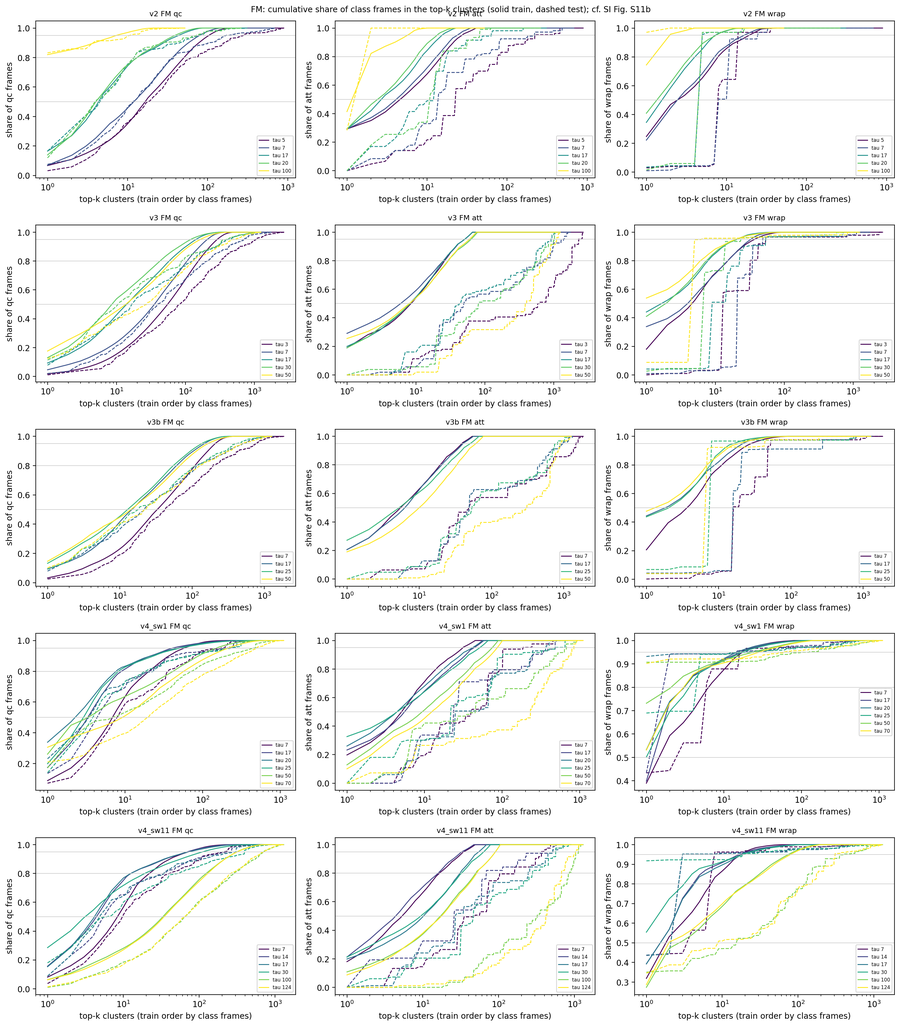

  fig figures/02_purity_recall__FM__base__all.png


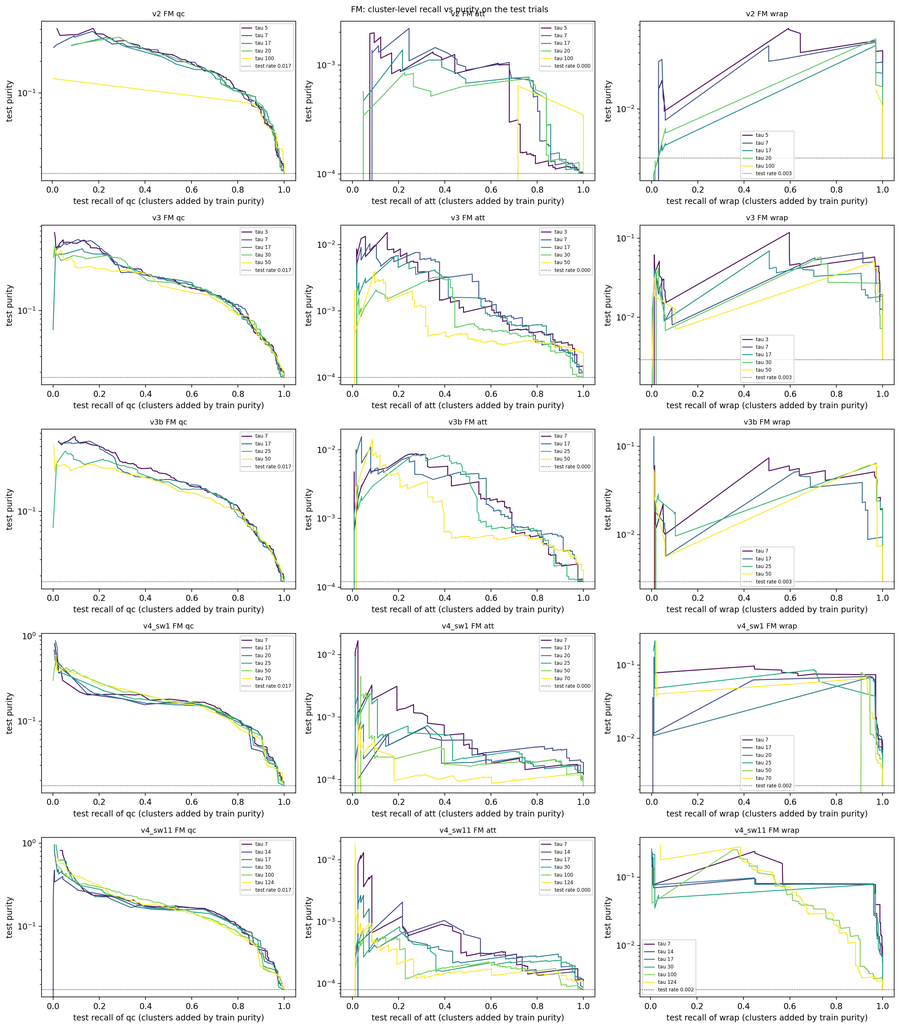

  fig figures/02_concentration__MM__base__all.png


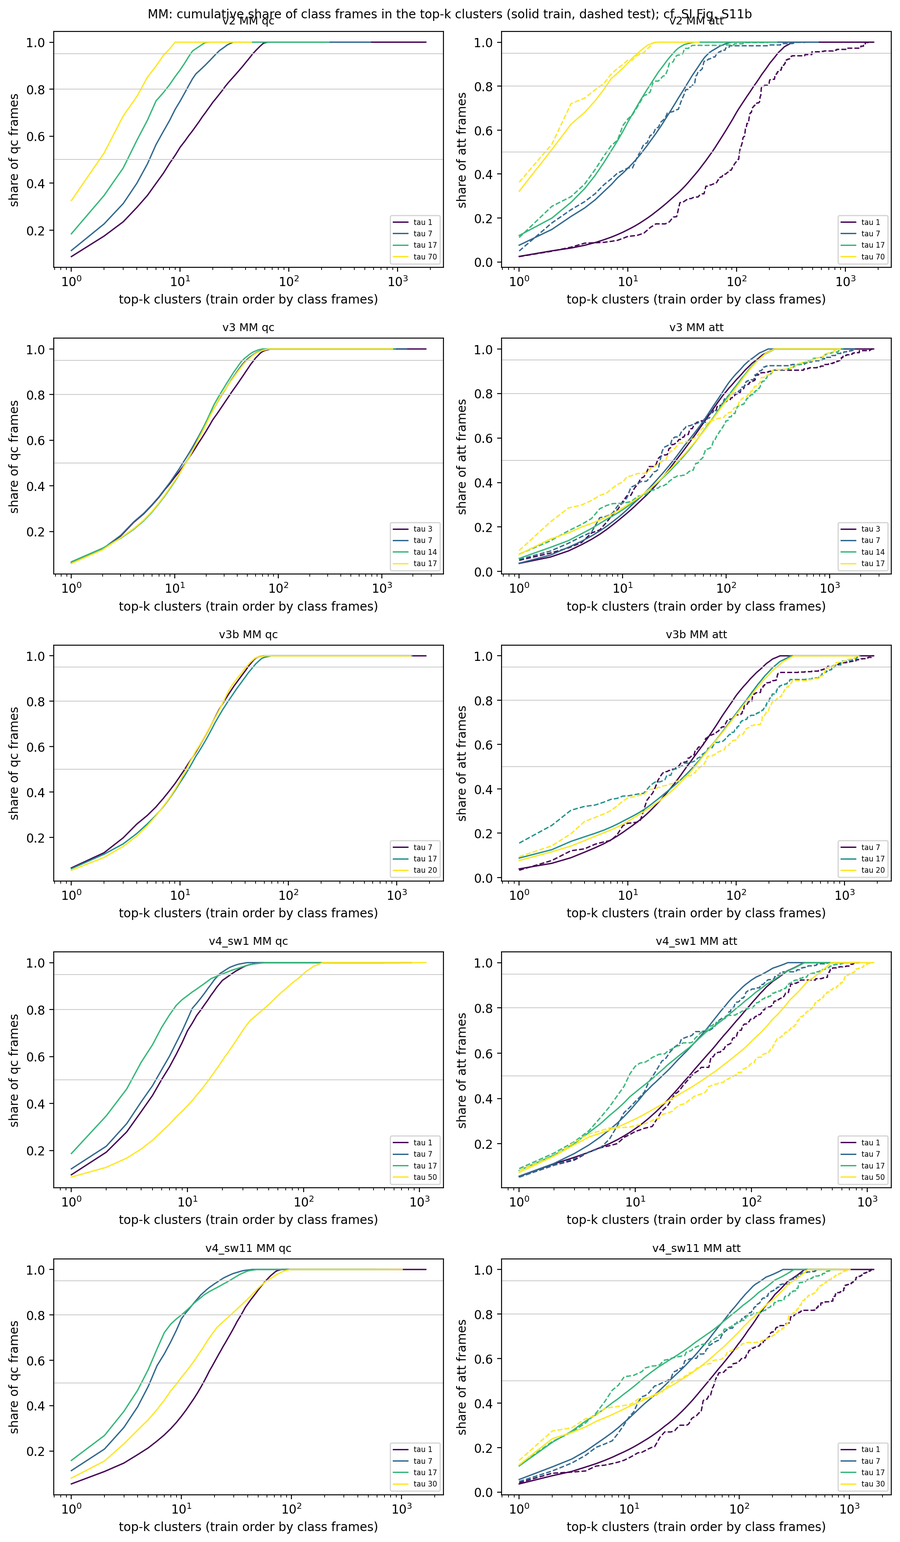

C:\Users\ReiterU\AppData\Local\Temp\ipykernel_15504\482951501.py:104: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=6)


  fig figures/02_purity_recall__MM__base__all.png


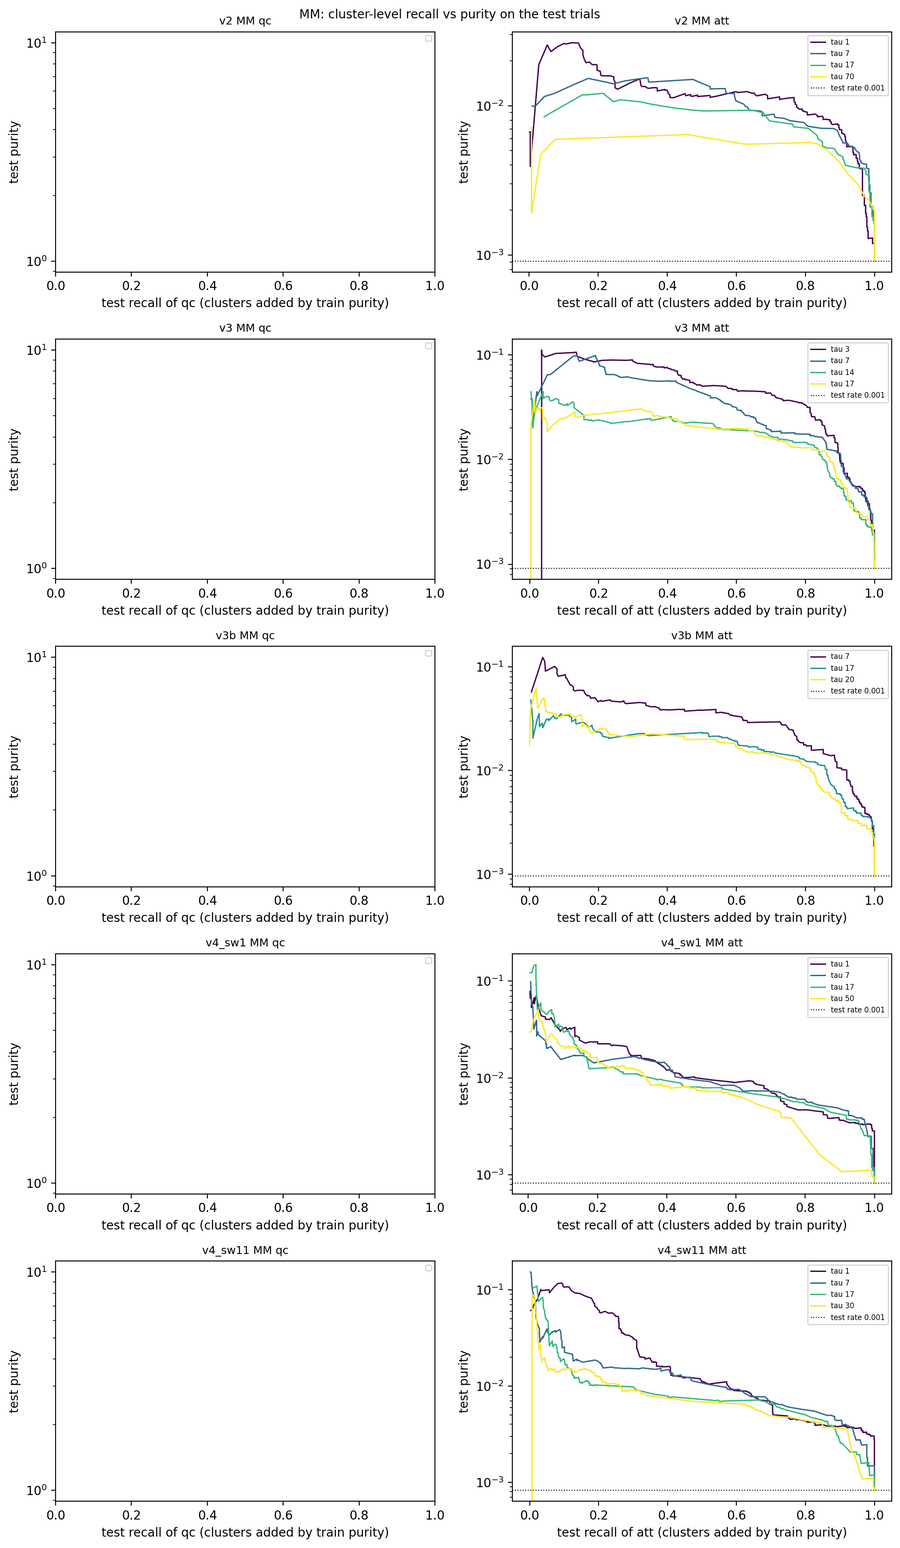

version unit  tau class   set  n_clusters  class_frames  class_frames_without_state_percent  base_rate  clusters_with_class  k50  purity_k50  frames_share_k50_percent  k80  purity_k80  frames_share_k80_percent  k95  purity_k95
     v2   FM    5    qc train         892         32364                               2.132      0.013                  195   17       0.139                     5.016   51       0.107                    10.676  104       0.068
     v2   FM    5    qc  test         892         18305                               0.874      0.017                  175   19       0.163                     5.292   66       0.112                    12.195  277       0.028
     v2   FM    5   att train         892           377                              19.363      0.000                   41    5       0.010                     0.685   16       0.004                     2.874   28       0.003
     v2   FM    5   att  test         892           132                              19.697 

In [4]:
# Step 2: concentration and purity of each class over the train clusters.
rows, top_rows, curves = [], [], {}
for ver, folder in RUNS.items():
    for unit in UNITS:
        files = run_files(folder, unit)
        if files is None or not files["taus"]:
            print(f"skip {ver} {unit}: no saved clusters")
            continue
        mic = {s: load_npz(files[s]) for s in ("train", "test")}
        ylab = {s: labels_for(mic[s]) for s in mic}
        for tau, csv in files["taus"].items():
            tab = pd.read_csv(csv).sort_values("state")
            lab = tab["cluster"].to_numpy(np.int64)
            k = int(lab.max()) + 1
            cl = {s: np.where(mic[s]["state"] >= 0, lab[np.clip(mic[s]["state"], 0, None)], -1) for s in mic}
            for c in CLASSES:
                y = {s: P4.detection_target(ylab[s], c) for s in mic}
                pos_tr = np.bincount(cl["train"][(cl["train"] >= 0) & (y["train"] == 1)], minlength=k)
                if pos_tr.sum() < MIN_POS:
                    continue
                n_lab_tr = np.bincount(cl["train"][(cl["train"] >= 0) & (y["train"] >= 0)], minlength=k)
                base_tr = pos_tr.sum() / max(n_lab_tr.sum(), 1)
                order = np.lexsort((np.arange(k), -pos_tr))                      # by train class frames
                purity_tr = (pos_tr + PRIOR_FRAMES * base_tr) / (n_lab_tr + PRIOR_FRAMES)
                order_p = np.lexsort((np.arange(k), -purity_tr))                 # by shrunk train purity
                for s in ("train", "test"):
                    yy, cc = y[s], cl[s]
                    n_pos_all = int((yy == 1).sum())
                    if n_pos_all < MIN_POS:
                        continue
                    pos = np.bincount(cc[(cc >= 0) & (yy == 1)], minlength=k).astype(float)
                    nlab = np.bincount(cc[(cc >= 0) & (yy >= 0)], minlength=k).astype(float)
                    nall = np.bincount(cc[cc >= 0], minlength=k).astype(float)
                    base = pos.sum() / max(nlab.sum(), 1)
                    cp = np.cumsum(pos[order]) / max(pos.sum(), 1)
                    curves[(ver, unit, tau, c, s)] = cp
                    r = {"version": ver, "unit": unit, "tau": tau, "class": c, "set": s, "n_clusters": k,
                         "class_frames": n_pos_all, "class_frames_without_state_percent": 100 * float(((yy == 1) & (cc < 0)).mean() / max((yy == 1).mean(), 1e-12)),
                         "base_rate": base,
                         "clusters_with_class": int((pos > 0).sum())}
                    for q in COVER:
                        n = int(np.searchsorted(cp, q - 1e-12) + 1)
                        sel = order[:n]
                        r[f"k{int(q * 100)}"] = n
                        r[f"purity_k{int(q * 100)}"] = pos[sel].sum() / max(nlab[sel].sum(), 1)
                        r[f"frames_share_k{int(q * 100)}_percent"] = 100 * nall[sel].sum() / max(nall.sum(), 1)
                    rows.append(r)
                    # purity-ranked curve (test only is plotted)
                    rec = np.cumsum(pos[order_p]) / max(pos.sum(), 1)
                    pur = np.cumsum(pos[order_p]) / np.maximum(np.cumsum(nlab[order_p]), 1)
                    curves[(ver, unit, tau, c, s, "pr")] = (rec, pur, base)
                    if s == "train":
                        for rank, ci in enumerate(order[:TOP_N]):
                            top_rows.append({"version": ver, "unit": unit, "tau": tau, "class": c, "rank": rank,
                                             "cluster": int(ci), "cluster_frames": int(nall[ci]),
                                             "cluster_frame_share_percent": 100 * nall[ci] / nall.sum(),
                                             "class_frames": int(pos[ci]), "class_share_percent": 100 * pos[ci] / pos.sum(),
                                             "purity": pos[ci] / max(nlab[ci], 1),
                                             "enrichment": (pos[ci] / max(nlab[ci], 1)) / max(base, 1e-12)})
        print(f"{ver} {unit}: taus {list(files['taus'])}")
CONC = pd.DataFrame(rows)
TOP = pd.DataFrame(top_rows)
L.save_csv(CONC, "02", "concentration", "all", "base", "all")
L.save_csv(TOP, "02", "top_clusters", "all", "base", "all")

vers = [v for v in RUNS if v in set(CONC["version"])]
for unit in UNITS:
    cls = [c for c in CLASSES if ((CONC["unit"] == unit) & (CONC["class"] == c)).any()]
    if not cls:
        continue
    for kind in ("concentration", "purity_recall"):
        fig, axes = plt.subplots(len(vers), len(cls), figsize=(5.2 * len(cls), 3.6 * len(vers)), squeeze=False)
        for i, ver in enumerate(vers):
            taus = sorted(CONC[(CONC["version"] == ver) & (CONC["unit"] == unit)]["tau"].unique())
            cmap = plt.get_cmap("viridis", max(len(taus), 2))
            for j, c in enumerate(cls):
                ax = axes[i, j]
                for t_i, tau in enumerate(taus):
                    col = cmap(t_i)
                    if kind == "concentration":
                        for s, ls in (("train", "-"), ("test", "--")):
                            cp = curves.get((ver, unit, tau, c, s))
                            if cp is not None:
                                ax.plot(np.arange(1, len(cp) + 1), cp, ls, color=col, lw=1.1,
                                        label=f"tau {tau}" if s == "train" else None)
                    else:
                        v = curves.get((ver, unit, tau, c, "test", "pr"))
                        if v is not None:
                            ax.plot(v[0], v[1], color=col, lw=1.1, label=f"tau {tau}")
                            base = v[2]
                if kind == "concentration":
                    for q in COVER:
                        ax.axhline(q, color="0.8", lw=0.7)
                    ax.set_xscale("log")
                    ax.set_xlabel("top-k clusters (train order by class frames)")
                    ax.set_ylabel(f"share of {c} frames")
                else:
                    if any((ver, unit, t, c, "test", "pr") in curves for t in taus):
                        ax.axhline(base, color="k", ls=":", lw=0.8, label=f"test rate {base:.3f}")
                    ax.set_yscale("log")
                    ax.set_xlabel(f"test recall of {c} (clusters added by train purity)")
                    ax.set_ylabel("test purity")
                ax.set_title(f"{ver} {unit} {c}", fontsize=9)
                ax.legend(fontsize=6)
        what = ("cumulative share of class frames in the top-k clusters (solid train, dashed test); cf. SI Fig. S11b"
                if kind == "concentration" else "cluster-level recall vs purity on the test trials")
        fig.suptitle(f"{unit}: {what}", fontsize=10)
        fig.tight_layout()
        p = L.save_fig(fig, "02", kind, unit, "base", "all")
        display(IPImage(filename=str(L.thumbs / p.name)))

show = ["version", "unit", "tau", "class", "set", "n_clusters", "class_frames", "class_frames_without_state_percent",
        "base_rate", "clusters_with_class", "k50", "purity_k50", "frames_share_k50_percent", "k80", "purity_k80",
        "frames_share_k80_percent", "k95", "purity_k95"]
print(CONC[show].round(3).to_string(index=False))

## Step 3 — 文件清单

In [5]:
print("output folder:", L.root)
for sub in ("figures", "data"):
    files = sorted(p.name for p in (L.root / sub).iterdir())
    print(f"\n{sub}/ ({len(files)} files)")
    for f in files:
        print("  ", f)

output folder: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\outputs\20261108_cluster_concentration_v2v3v3bv4

figures/ (4 files)
   02_concentration__FM__base__all.png
   02_concentration__MM__base__all.png
   02_purity_recall__FM__base__all.png
   02_purity_recall__MM__base__all.png

data/ (2 files)
   02_concentration__all__base__all.csv
   02_top_clusters__all__base__all.csv
